<a href="https://colab.research.google.com/github/thahakm/domino-score-tracker/blob/main/Bank_customer_churn_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

***Bank Customer Churn eda Analysis ***

**: Perform Exploratory Data Analysis (EDA) on a 10,000-customer retail banking dataset to identify the demographic, financial, and behavioral patterns driving customer churn.**

In [ ]:
import pandas as pd
df = pd.read_csv("/content/messy_churn.csv")

In [ ]:
df

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,5398,15638513,Palermo,15.0,France,Female,-1.0,7.0,142856.95,2,0,0,"$38,019.74",0
1,3078,15673367,Humffray,999.0,Germany,Male,200.0,6.0,132603.36,1,1,0,"$55,775.72",0
2,6051,15626414,Russell,1200.0,France,Male,-5.0,6.0,98862.54,1,1,0,151516.7,0
3,6503,15590286,Fairley,0.0,France,FEMALE,200.0,2.0,125879.29,1,1,0,"$93,203.43",0
4,3602,15747208,Watt,1200.0,France,Male,-5.0,6.0,0.00,1,1,0,"$93,568.77",1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10295,5735,15596647,Henderson,768.0,France,Male,54.0,8.0,69712.74,1,1,1,"$69,381.05",0
10296,5192,15681075,Chukwualuka,682.0,France,Female,58.0,1.0,0.00,1,1,1,706.5,0
10297,5391,15573851,Macrossan,735.0,?,Female,38.0,1.0,0.00,3,0,0,92220.12,1
10298,861,15807663,McGregor,667.0,France,Male,43.0,8.0,190227.46,1,1,0,97508.04,1


In [ ]:
df.dtypes

,0
RowNumber,int64
CustomerId,int64
Surname,object
CreditScore,float64
Geography,object
Gender,object
Age,float64
Tenure,float64
Balance,float64
NumOfProducts,int64


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10300 entries, 0 to 10299
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10300 non-null  int64  
 1   CustomerId       10300 non-null  int64  
 2   Surname          10300 non-null  object 
 3   CreditScore      9695 non-null   float64
 4   Geography        10216 non-null  object 
 5   Gender           10300 non-null  object 
 6   Age              9669 non-null   float64
 7   Tenure           9678 non-null   float64
 8   Balance          9690 non-null   float64
 9   NumOfProducts    10300 non-null  int64  
 10  HasCrCard        10300 non-null  int64  
 11  IsActiveMember   10300 non-null  int64  
 12  EstimatedSalary  9695 non-null   object 
 13  Exited           10300 non-null  int64  
dtypes: float64(4), int64(6), object(4)
memory usage: 1.1+ MB


In [ ]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,Exited
count,10300.000000,1.030000e+04,9695.000000,9669.000000,9678.000000,9690.000000,10300.000000,10300.000000,10300.000000,10300.000000
mean,5000.223204,1.569102e+07,650.260650,39.005792,5.027382,76710.620204,1.529806,0.704951,0.514757,0.203883
std,2887.127299,7.196620e+04,100.057211,11.564732,2.895189,62325.214994,0.582278,0.456087,0.499806,0.402903
min,1.000000,1.556570e+07,0.000000,-5.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
25%,2504.750000,1.562860e+07,583.000000,32.000000,3.000000,0.000000,1.000000,0.000000,0.000000,0.000000
50%,5001.500000,1.569076e+07,652.000000,37.000000,5.000000,97370.100000,1.000000,1.000000,1.000000,0.000000
75%,7506.250000,1.575334e+07,718.000000,44.000000,8.000000,127641.310000,2.000000,1.000000,1.000000,0.000000
max,10000.000000,1.581569e+07,1200.000000,200.000000,10.000000,250898.090000,4.000000,1.000000,1.000000,1.000000


In [ ]:
df.shape

(10300, 14)

In [ ]:
import numpy as np

df['Geography'] = df['Geography'].astype(str).str.strip().str.title()

# Fix known abbreviations/short forms
df['Geography'] = df['Geography'].replace({'Ger': 'Germany'})

# Replace placeholder strings with actual NaN
hidden_nulls = ['?', 'Unknown', 'None', 'Nan', 'N/A', '-']
df['Geography'] = df['Geography'].replace(hidden_nulls, np.nan)
df['Geography'] = df['Geography'].fillna(df['Geography'].mode()[0])

In [ ]:
# 1. Clean

df['Gender'] = df['Gender'].astype(str).str.strip().str.title()

# df['Gender'] = df['Gender'].replace("nan", np.nan)
df['Gender'] = df['Gender'].replace({
    'F':'Female',
    'M':'Male'

})


In [ ]:
df['Tenure'] = df['Tenure'].fillna(df['Tenure'].mode()[0])

In [ ]:
df['Balance'] = df['Balance'].fillna(df['Balance'].mean())

In [ ]:
df['EstimatedSalary'] = (
    df['EstimatedSalary']
    .astype(str)
    .str.replace('$', '', regex=False)
    .str.replace(',', '', regex=False)
    .str.strip()
)

# 2. Convert to float64, converting any remaining invalid strings (like 'nan', '?') to proper NaN
df['EstimatedSalary'] = pd.to_numeric(df['EstimatedSalary'], errors='coerce')
df['EstimatedSalary'] =df['EstimatedSalary'].fillna(df['EstimatedSalary'].mode()[0])

In [ ]:
for col in df.columns:
  print(col)
  print(df[col].unique())
  print("\n")

RowNumber
[5398 3078 6051 ... 5391  861 7271]


CustomerId
[15638513 15673367 15626414 ... 15573851 15807663 15706268]


Surname
['Palermo' 'Humffray' 'Russell' ... 'Manners' 'Winn' 'Macrossan']


CreditScore
[  15.  999. 1200.    0.  518.  582.  738.  628.  622.  549.  577.  669.
  670.  640.  682.  543.  593.  807.  850.  672.  773.  774.  688.  602.
  587.  675.  667.  558.  680.  533.   nan  604.  642.  714.  624.  554.
  732.  674.  486.  744.  683.  498.  691.  616.  841.  609.  555.  600.
  766.  726.  718.  793.  645.  731.  457.  699.  754.  528.  681.  560.
  757.  823.  723.  729.  725.  514.  763.  802.  473.  596.  666.  698.
  597.  573.  759.  619.  685.  711.  445.  697.  779.  794.  707.  589.
  439.  641.  708.  653.  643.  686.  768.  719.  510.  706.  505.  746.
  647.  646.  684.  608.  491.  812.  797.  511.  709.  644.  479.  808.
  792.  712.  705.  424.  677.  692.  743.  806.  630.  785.  351.  550.
  559.  517.  631.  422.  591.  789.  665.  520.  583.  702. 

In [ ]:
df.duplicated().sum()
df = df.drop_duplicates()
df.duplicated().sum()

np.int64(0)

In [ ]:
# for col in df.columns:
#   print(df[col].unique())
#   print("\n")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns


In [ ]:
# Credit scores valid range: 300 to 850
# Replace values outside this range with NaN for imputation
invalid_scores = (df['CreditScore'] < 300) | (df['CreditScore'] > 850)
df.loc[invalid_scores, 'CreditScore'] = np.nan

# Age valid range: 18 to 100
invalid_age = (df['Age'] < 18) | (df['Age'] > 100)
df.loc[invalid_age, 'Age'] = np.nan

print("Outliers set to NaN:")
print(f"CreditScore NaNs: {df['CreditScore'].isna().sum()}")
print(f"Age NaNs: {df['Age'].isna().sum()}")

Outliers set to NaN:
CreditScore NaNs: 624
Age NaNs: 656


In [ ]:
df['Age'] = df['Age'].fillna(df['Age'].mode()[0])

/tmp/ipykernel_1802/401972750.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['Age'] = df['Age'].fillna(df['Age'].mode()[0])


In [ ]:
df['CreditScore'] = df['CreditScore'].fillna(df['CreditScore'].mean())

/tmp/ipykernel_1802/2163766193.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['CreditScore'] = df['CreditScore'].fillna(df['CreditScore'].mean())


Goal: Identify root drivers behind customer churn (Exited) and build actionable, data-driven retention strategies.

In [ ]:
Eda = df.drop(
      columns=["RowNumber", "CustomerId", "Surname"]
)

/tmp/ipykernel_1802/2590807806.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=Eda, x="Exited",  palette=["g", "r"], legend=False)


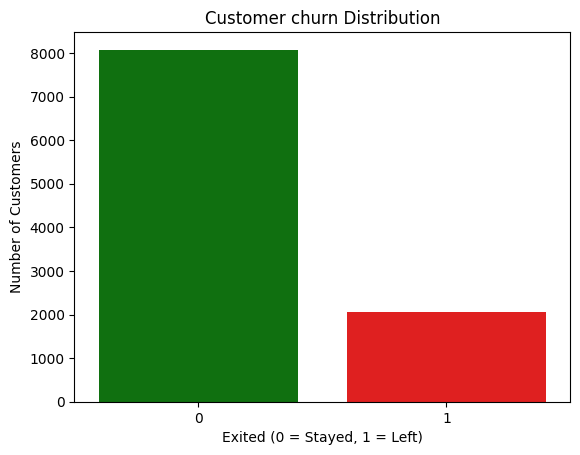

In [ ]:
# How many customers left the bank?
sns.countplot(data=Eda, x="Exited",  palette=["g", "r"], legend=False)
plt.title("Customer churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")
plt.show()

Overall churn rate stands at 20.4% (2,037 out of 10,000 customers).
Retained Customers: 79.6% (7,963 customers retained)

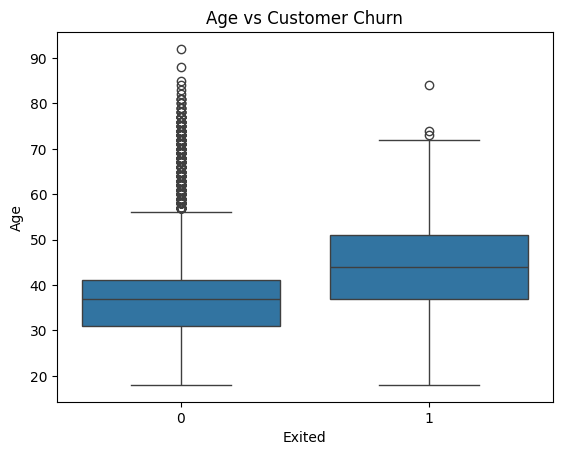

In [ ]:
# 2,Does age relate to churn?
sns.boxplot(data=Eda,x="Exited",y="Age")
plt.title("Age vs Customer Churn")
plt.show()

The median age for retained customers (0) is around 36.

The median age for churned customers (1) is noticeably higher at around 45.

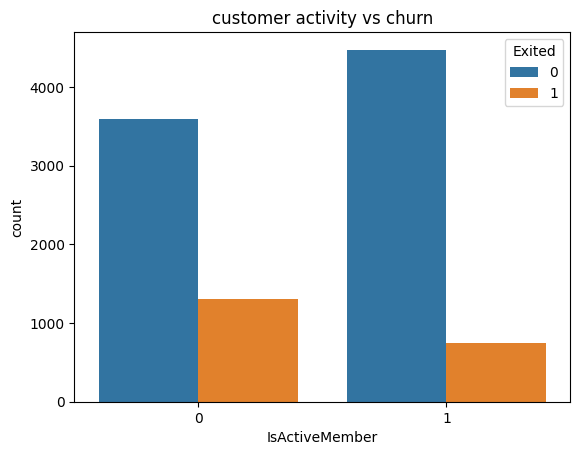

In [ ]:
# Does activity relate to churn?
sns.countplot(data=Eda,x="IsActiveMember",hue="Exited")
plt.title("customer activity vs churn")
plt.show()

In [ ]:
for col in Eda.columns:
    print(col, ":", Eda[col].nunique())

CreditScore : 461
Geography : 3
Gender : 2
Age : 70
Tenure : 11
Balance : 6024
NumOfProducts : 4
HasCrCard : 2
IsActiveMember : 2
EstimatedSalary : 9428
Exited : 2


In [ ]:
Eda["Exited"].value_counts(normalize=True)*100

,proportion
Exited,
0,79.688117
1,20.311883


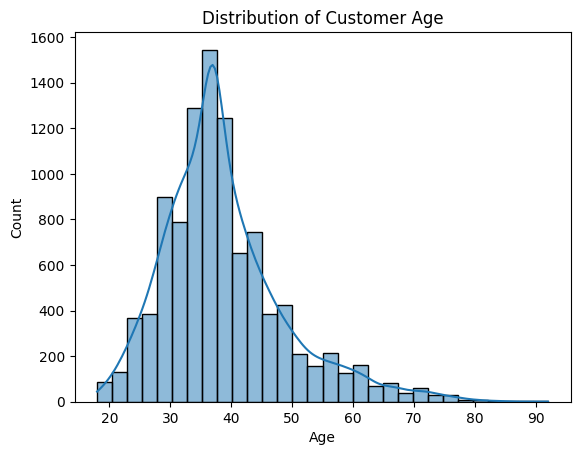

In [ ]:
# Analysing Neumerical columns
sns.histplot(data=Eda, x="Age", bins=30,kde=True)
plt.title("Distribution of Customer Age")
plt.show()

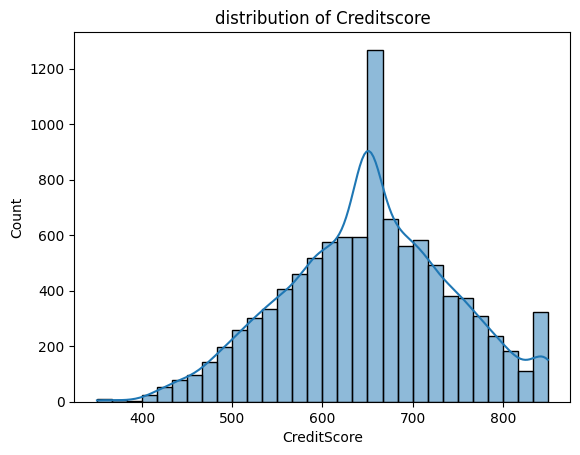

In [ ]:
sns.histplot(data=Eda,x="CreditScore",bins=30,kde=True)
plt.title("distribution of Creditscore")
plt.show()

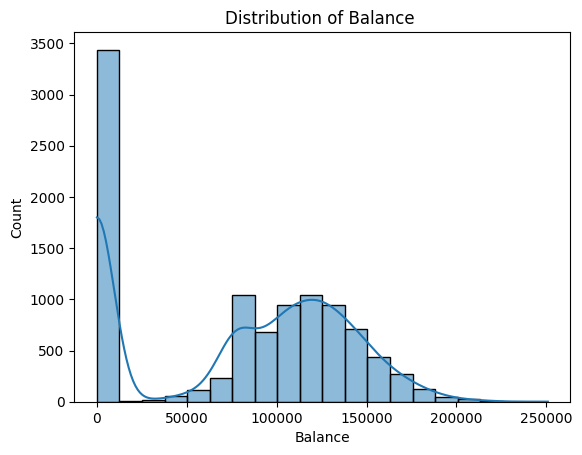

In [ ]:
sns.histplot(data=Eda,x="Balance",bins=20
             ,kde=True)
plt.title("Distribution of Balance ")
plt.show()

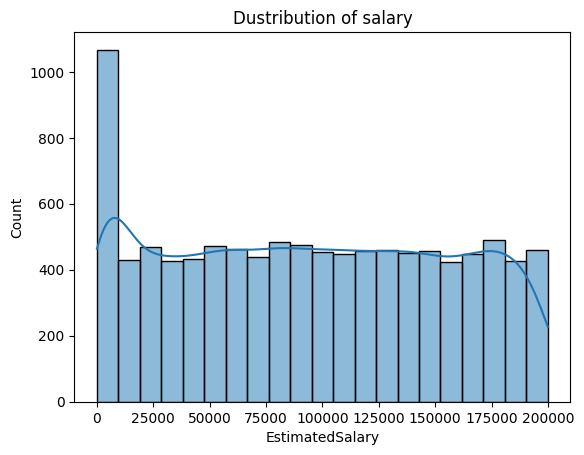

In [ ]:
sns.histplot(data=Eda ,x="EstimatedSalary",kde=True)
plt.title("Dustribution of salary")
plt.show()

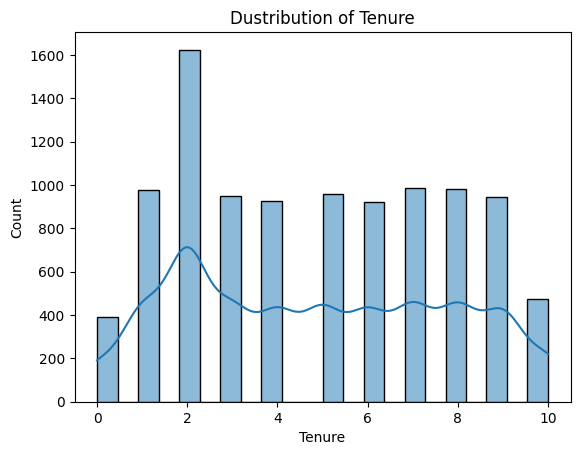

In [ ]:

sns.histplot(data=Eda ,x="Tenure",kde=True)
plt.title("Dustribution of Tenure")
plt.show()


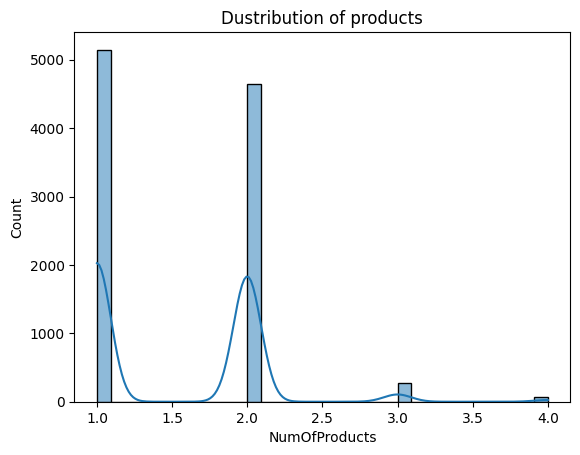

In [ ]:
sns.histplot(data=Eda ,x="NumOfProducts",kde=True)
plt.title("Dustribution of products")
plt.show()


/tmp/ipykernel_1802/876969195.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  br=sns.countplot(data=Eda, x="Geography", palette=["red", "green", "orange"])


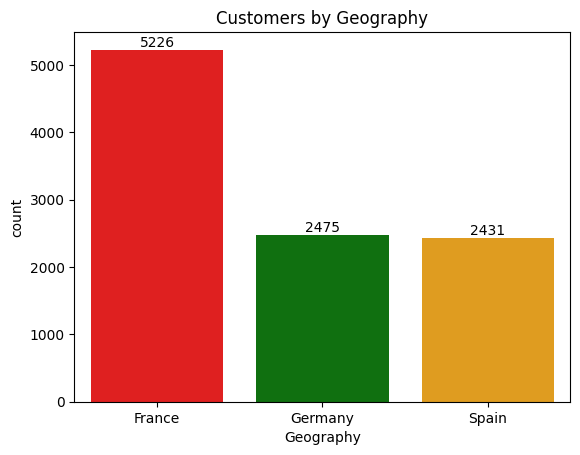

In [ ]:

br=sns.countplot(data=Eda, x="Geography", palette=["red", "green", "orange"])
plt.title("Customers by Geography")
for bars in br.containers:
  br.bar_label(bars)
plt.show()

/tmp/ipykernel_1802/3494433865.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=Eda,x="Gender",palette=["green","yellow"])


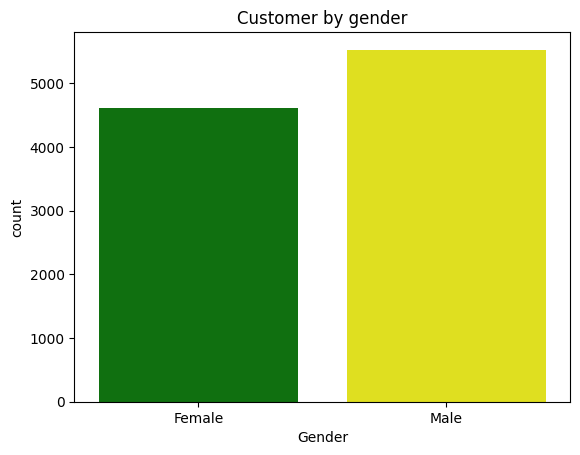

In [ ]:
# , and IsActiveMember.
sns.countplot(data=Eda,x="Gender",palette=["green","yellow"])
plt.title("Customer by gender")
plt.show()

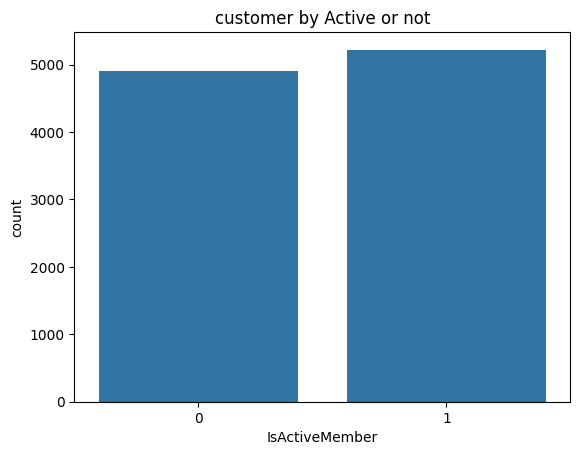

In [ ]:
sns.countplot(data=Eda,x="IsActiveMember")
plt.title("customer by Active or not")
plt.show()


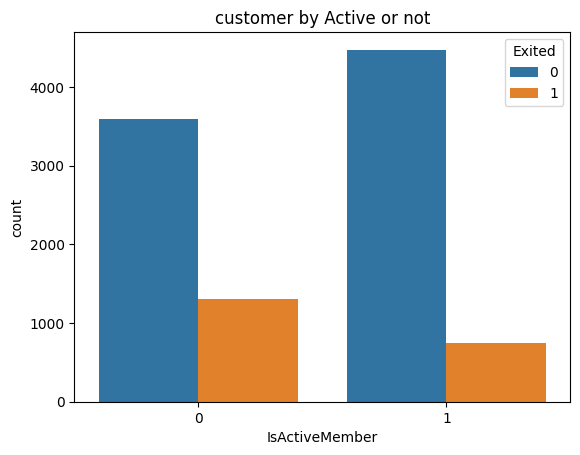

In [ ]:
sns.countplot(data=Eda,x="IsActiveMember",hue="Exited")
plt.title("customer by Active or not")
plt.show()

Active Members (IsActiveMember = 1): 14.3% churn.

Inactive Members (IsActiveMember = 0): 26.9% churn.

In [ ]:
Eda["Exited"].value_counts()

,count
Exited,
0,8074
1,2058


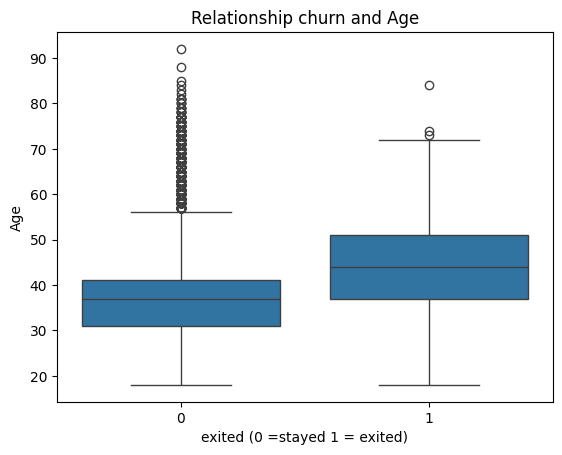

In [ ]:
sns.boxplot(data=Eda,x="Exited",y="Age")
plt.title("Relationship churn and Age")
plt.xlabel("exited (0 =stayed 1 = exited)")
plt.show()

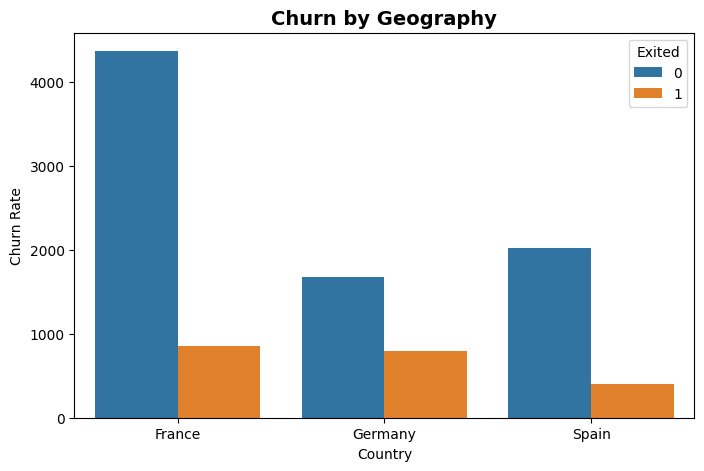

In [ ]:

plt.figure(figsize=(8, 5))
sns.countplot(data=Eda, x="Geography", hue="Exited")
plt.title("Churn by Geography",fontsize=14, fontweight="bold")
plt.xlabel("Country")
plt.ylabel("Churn Rate")
plt.show()

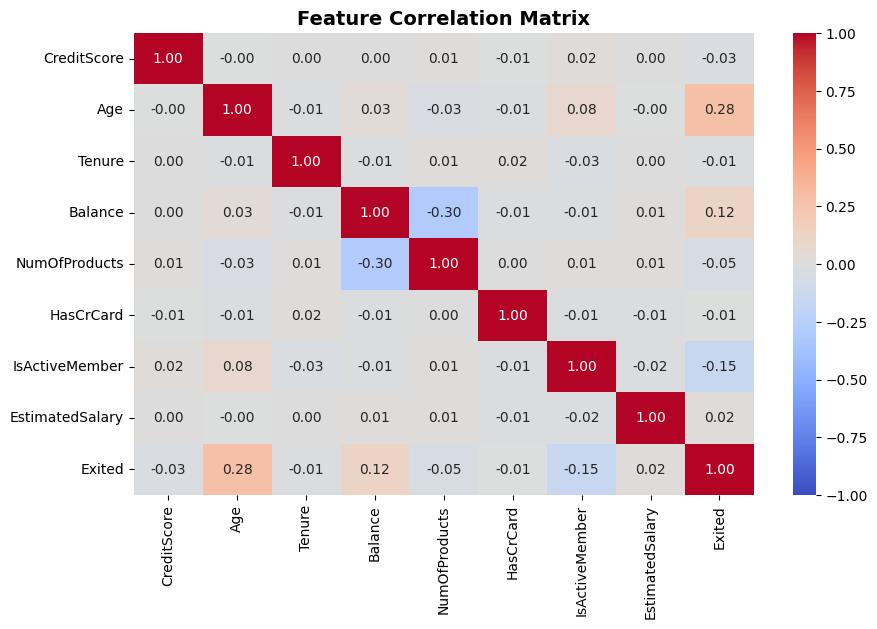

In [ ]:
plt.figure(figsize=(10, 6))

numeric_cols = Eda.select_dtypes(include=['float64', 'int64']).columns
cols_to_corr = [c for c in numeric_cols ]

sns.heatmap(df[cols_to_corr].corr(), annot=True, fmt=".2f", cmap='coolwarm',vmin=-1, vmax=1)
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.show()

Core EDA Findings
1. Baseline Metric

    Overall Churn Rate is ~20.4%: Out of 10,000 customers, 2,037 left the bank, while 7,963 stayed (roughly a 1:4 ratio).

2. Top Drivers of Churn

    Age is the Strongest Demographic Driver (r=0.24):   
    PNG

        Retained customers have an average age of ~37 years (median 36).   
        PNG

        Churned customers have an average age of ~45 years (median 45).   
        PNG

        Takeaway: Middle-aged and older customers are at a much higher risk of leaving.   
       

    Geography Matters (Germany is High-Risk):

        Germany: 32.4% churn rate — almost 1 in every 3 customers exits.

        France: 16.2% churn rate.

        Spain: 16.7% churn rate.

        Takeaway: Customers in Germany are twice as likely to leave compared to France or Spain.

    
    Account Engagement (IsActiveMember):

        Inactive members have an attrition rate of 26.9%.

        Active members have an attrition rate of 14.3%.

        Takeaway: Active engagement cuts the churn rate nearly in half.

    Gender Disparity:

        Female customers churn at 25.1%.

        Male customers churn at 16.5%.